1. Environment Setup

In [2]:
# 1.1 Installing required modules

!pip install kagglehub numpy pandas matplotlib seaborn scikit-learn keras
!pip install tensorflow==2.15                                   # need this to be compatible with the gradio version
!pip install gradio==4.29.0                                     # for compatibility with the hugginface hub
!pip install huggingface_hub==0.23.0                            # for compatibility with the gradio
!pip install sweetviz                                           # for generatiung automated HTML report for EDA

ERROR: Invalid requirement: '#': Expected package name at the start of dependency specifier
    #
    ^
ERROR: Invalid requirement: '#': Expected package name at the start of dependency specifier
    #
    ^
ERROR: Invalid requirement: '#': Expected package name at the start of dependency specifier
    #
    ^
ERROR: Invalid requirement: '#': Expected package name at the start of dependency specifier
    #
    ^


In [3]:
# 1.2 Importing essential libraries 

import numpy as np                                              # NumPy: used for numerical operations, arrays, math calculations
import pandas as pd                                             # Pandas: used to load the dataset, clean data, perform EDA, and manipulate tables
import matplotlib.pyplot as plt                                 # Matplotlib: used for basic visualizations (plots, histograms, scatter plots)
import seaborn as sns                                           # Seaborn: used for advanced statistical visualizations (heatmaps, distributions)
import tensorflow as tf                                         # TensorFlow: used to build and train deep learning models

from sklearn.preprocessing import OneHotEncoder                 # OneHotEncoder: used to convert categorical features into binary vectors
from sklearn.preprocessing import StandardScaler                # StandardScaler: used to scale numeric features to have mean=0 and variance=1
from sklearn.model_selection import train_test_split            # Splits dataset into training and testing sets
from tensorflow.keras.models import Sequential                  # Sequential: used to define a linear stack of layers for deep learning models
from tensorflow.keras.layers import Dense                       # Dense: used to define fully connected layers in deep learning models
from sklearn.preprocessing import LabelEncoder, StandardScaler  # Encodes categorical features + scales numeric features
from sklearn.metrics import (classification_report,             # Evaluates classification model performance
                             mean_absolute_error,               # Regression metric: average absolute error
                             mean_squared_error,                # Regression metric: average squared error
                             r2_score)                          # Regression metric: goodness of fit (0–1)
from sklearn.cluster import KMeans                              # KMeans: used for customer segmentation (clustering)
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix   # Importing required metrics for classification evaluation
from sklearn.metrics import silhouette_score                    # Importing silhouette score for evaluating clustering performance



import tensorflow as tf                                         # TensorFlow: used to build and train deep learning models
from tensorflow import keras                                    # Keras: high-level API for building and training deep learning models
from keras import layers                                        # Layers: used to define the architecture of deep learning models

import kagglehub as kb                                          # KaggleHub: used to download the Diamonds dataset directly from Kaggle

import gradio as gr                                             # Gradio: used to build the GUI/web app for diamond price prediction


2. Data Collection

In [4]:
# 2.1 Downloading diamond dataset from kagglehub and loading it into a pandas DataFrame

path = kb.dataset_download("shivam2503/diamonds")               # Downloads the Diamonds dataset from Kaggle and saves it to the specified path
df = pd.read_csv(path + "/diamonds.csv")                        # Loads the Diamonds dataset into a pandas DataFrame for further analysis and modeling
df.rename(columns={'Unnamed: 0': 'Serial Number'}, inplace=True)    # Renames the 'Unnamed: 0' column to 'Serial Number' for better clarity

3. Exploratory Data Analysis (EDA)

In [5]:
# 3.1 EDA Summary Table

eda_summary = pd.DataFrame({                                    # Creates a summary table for EDA (Exploratory Data Analysis) with various statistics for each column in the DataFrame
    'dtype': df.dtypes,
    'missing': df.isnull().sum(),
    'unique': df.nunique(),
    'mean': df.mean(numeric_only=True),
    'std': df.std(numeric_only=True),
    'min': df.min(numeric_only=True),
    'max': df.max(numeric_only=True),
    'mode': df.mode().iloc[0],
    'median': df.median(numeric_only=True),
    'range': df.max(numeric_only=True) - df.min(numeric_only=True),
})
eda_summary.to_csv("EDA_Summary.csv", index=True)               # Saves the EDA summary table as a CSV file named "EDA_Summary.csv" for further analysis and reference

# Generating an automated EDA report using Sweetviz

import sweetviz as sv                                           # Sweetviz: used to generate an automated HTML report for EDA
df_sweetviz = df.drop(columns=['Serial Number'])                # Drops the 'Serial Number' column from the DataFrame for EDA report generation
report = sv.analyze(df_sweetviz)                                # Generates an automated EDA report for the Diamonds dataset using Sweetviz
report.show_html("EDA_Report.html")                             # Saves the EDA report as an HTML file named "EDA_Report.html" for further analysis and visualization

                                             |          | [  0%]   00:00 -> (? left)

Report EDA_Report.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


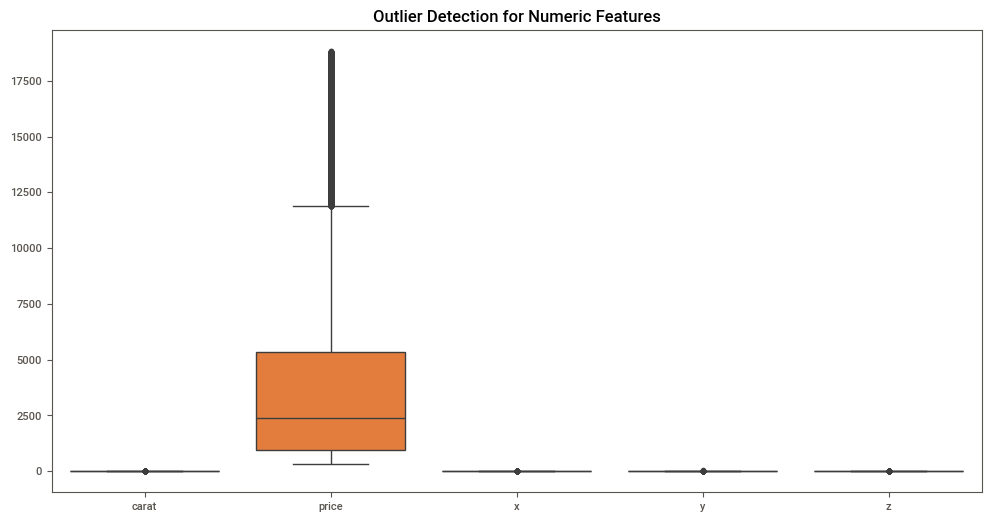

In [6]:
# 3.2 Outlier Detection for Numeric Features - Box Plot

plt.figure(figsize=(12,6))                                      # Creates a figure with the specified size for visualizing outliers in numeric features of the dataset
sns.boxplot(data=df[['carat','price','x','y','z']])             # Creates a boxplot for the numeric features 'carat', 'price', 'x', 'y', and 'z' in the dataset to visualize potential outliers
plt.title("Outlier Detection for Numeric Features")             # Adds the title to the boxplot for better understanding of the visualization
plt.show()                                                      # Displays the boxplot for outlier detection in numeric features of the dataset

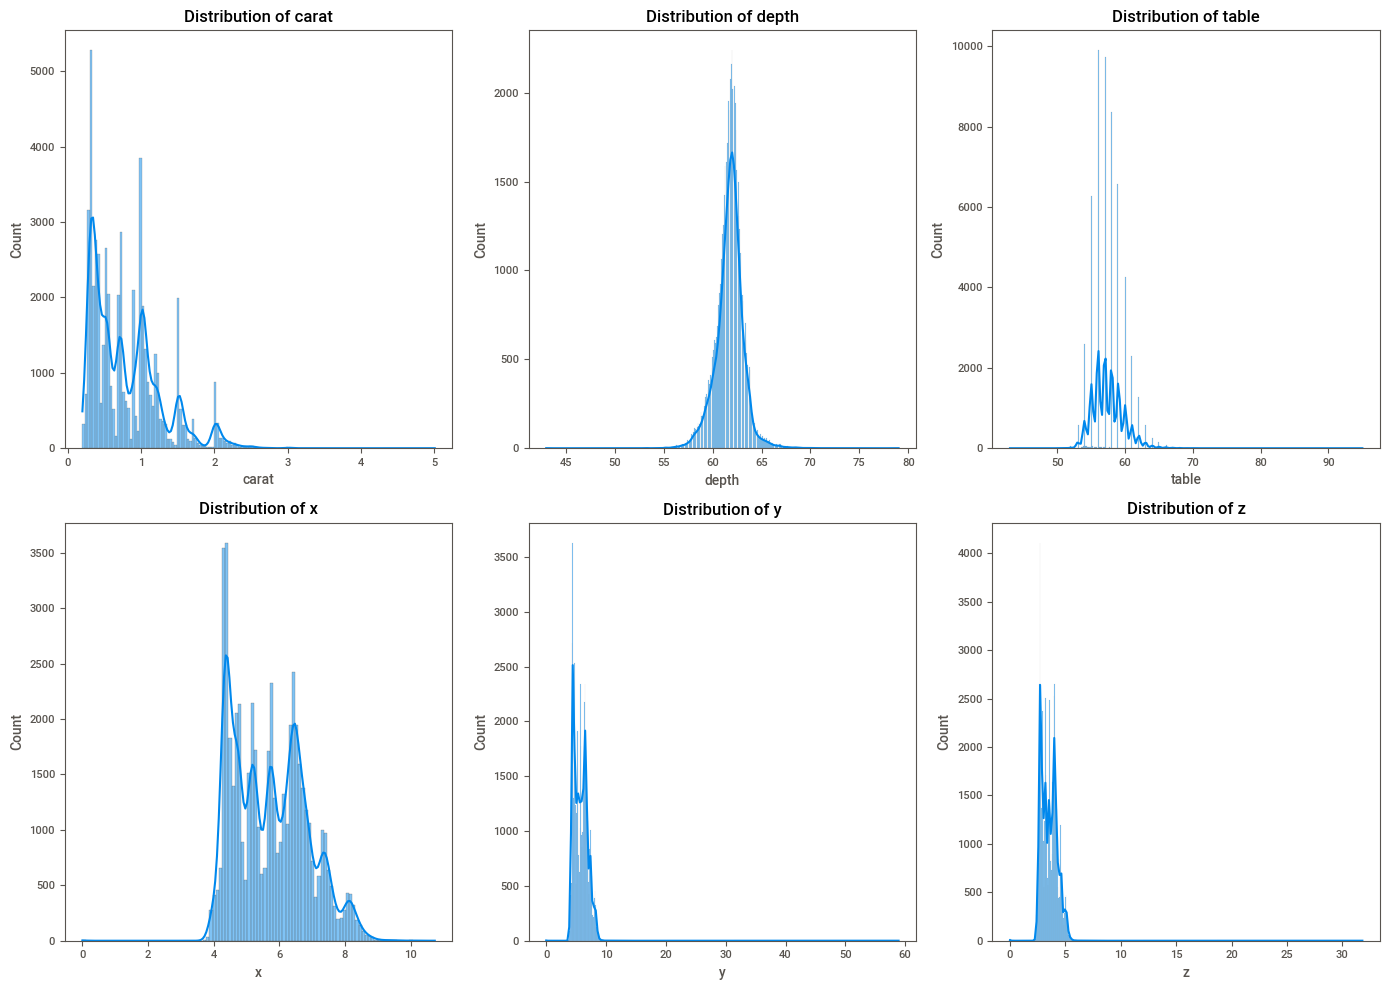

In [7]:
# 3.3 Data distribution visualization for numeric features - Histogram

features = ['carat', 'depth', 'table', 'x', 'y', 'z']           # Defines the list of numeric features for which the data distribution will be visualized
plt.figure(figsize=(14,10))                                     # Creates a figure with the specified size for visualizing the data distribution of numeric features in the dataset
for i, col in enumerate(features):                              # Iterates through the list of numeric features and creates a histogram for each feature to visualize its data distribution
    plt.subplot(2, 3, i+1)
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")

plt.tight_layout()                                              # Adjusts the layout of the subplots to prevent overlapping and ensure proper spacing between the plots
plt.show()                                                      # Displays the histograms for data distribution visualization of numeric features in the dataset

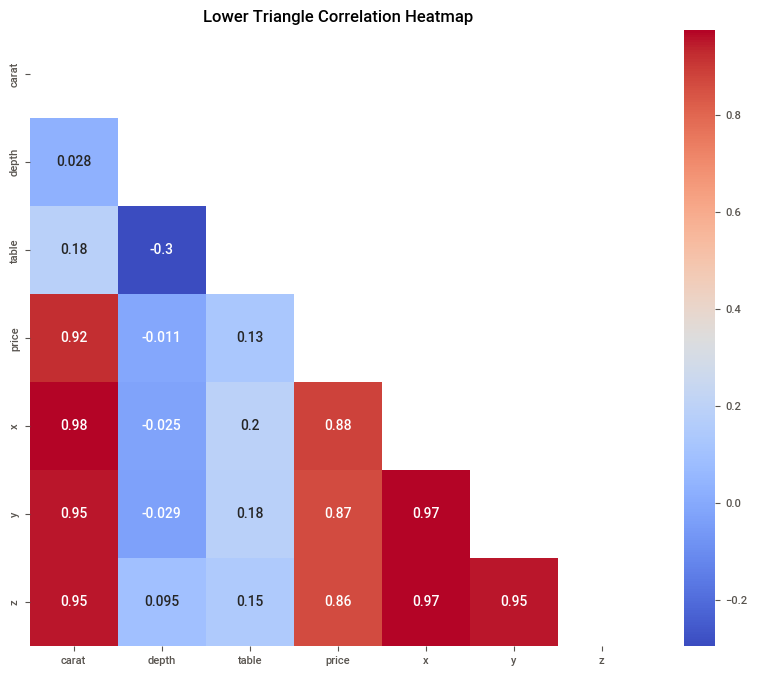

In [8]:
# 3.4 Correlation Heatmap for Numeric Features

df = df.drop(columns=['Serial Number'])                         # Drop the serial column first, its not required for the correlation analysis, as it is just an identifier and does not provide any meaningful information for correlation analysis
corr = df.corr(numeric_only=True)                               # Compute correlation matrix 
mask = np.triu(np.ones_like(corr, dtype=bool))                  # Create upper triangle mask, hiding the upper triangle of the correlation matrix to avoid redundancy in the heatmap visualization

plt.figure(figsize=(10, 8))                                     # Creates a figure with the specified size for visualizing the correlation heatmap of numeric features in the dataset
sns.heatmap(corr, mask=mask, annot=True, cmap="coolwarm", square=True)  # Creates a heatmap for the correlation matrix of numeric features in the dataset, with annotations, a specified color map, and square cells for better visualization
plt.title("Lower Triangle Correlation Heatmap")                 # Adds the title to the heatmap 
plt.show()                                                      # Displays the correlation heatmap 

4. Data Preprocessing

In [9]:
# 4.1 Checking for duplicate rows in the dataset

duplicate_count = df.duplicated().sum()                         # counts how many rows are exact duplicates of another row
print(f"Number of duplicate rows: {duplicate_count}")           # prints the count so we know if cleaning is needed

df = df.drop_duplicates()                                       # removes duplicate rows, keeping the first occurrence of each
df = df.reset_index(drop=True)                                  # resets the row index to be sequential again after dropping rows (avoids gaps in the index)

Number of duplicate rows: 146


In [10]:
# 4.2 Checking for physically impossible rows where a dimension is zero

invalid_rows = df[(df['x'] == 0) | (df['y'] == 0) | (df['z'] == 0)]  # filters rows where any dimension is 0
print(f"Rows with invalid zero dimensions: {len(invalid_rows)}")     # shows how many rows are affected

df = df[(df['x'] > 0) & (df['y'] > 0) & (df['z'] > 0)]          # keeps only rows where all three dimensions are greater than 0
df = df.reset_index(drop=True)                                  # resets index again after filtering out rows

Rows with invalid zero dimensions: 19


In [11]:
# 4.3 Encoding categorical features

categorical_cols = ['cut', 'color', 'clarity']                  # Defines the list of categorical columns to be encoded

encoder =OneHotEncoder(sparse_output=False, handle_unknown='ignore')   # Initialize OneHotEncoder to convert categorical features into binary vectors, dropping the first category to avoid multicollinearity
encoded = encoder.fit_transform(df[categorical_cols])           # Fit the encoder to the categorical columns and transform them into binary vectors

encoded_df = pd.DataFrame(encoded, columns=encoder.get_feature_names_out(categorical_cols))  # Create a new DataFrame from the encoded features with appropriate column names

df_encoded = pd.concat([df.drop(columns=categorical_cols), encoded_df], axis=1)  # Concatenate the original DataFrame (without categorical columns) and the encoded DataFrame along the columns

In [12]:
# 4.4 Scaling numeric features

numeric_cols = ['carat','depth','table','x','y','z']    # Defines the list of numeric columns to be scaled using StandardScaler, which standardizes features by removing the mean and scaling to unit variance

price_scaler = StandardScaler()                                       # Initializes the StandardScaler to scale numeric features to have mean=0 and variance=1, which is important for many machine learning algorithms that are sensitive to feature scales
scaled = price_scaler.fit_transform(df_encoded[numeric_cols])         # Fits the scaler to the numeric columns and transforms them into scaled values, ensuring that all numeric features are on a similar scale for better model performance

scaled_df = pd.DataFrame(scaled, columns=numeric_cols)          # Creates a new DataFrame from the scaled numeric features with appropriate column names, allowing for easy integration with the rest of the dataset

# Merging numeric and encoded features into a single DataFrame  

df_final = pd.concat([scaled_df, df_encoded.drop(columns=numeric_cols)], axis=1)   # Concatenates the scaled numeric DataFrame and the encoded categorical DataFrame along the columns to create a final DataFrame that contains all features (both numeric and categorical) in a format suitable for machine learning model training and evaluation
df_final = df_final.loc[:, ~df_final.columns.duplicated()]      # 

In [13]:
print(df_final.columns)


Index(['carat', 'depth', 'table', 'x', 'y', 'z', 'price', 'cut_Fair',
       'cut_Good', 'cut_Ideal', 'cut_Premium', 'cut_Very Good', 'color_D',
       'color_E', 'color_F', 'color_G', 'color_H', 'color_I', 'color_J',
       'clarity_I1', 'clarity_IF', 'clarity_SI1', 'clarity_SI2', 'clarity_VS1',
       'clarity_VS2', 'clarity_VVS1', 'clarity_VVS2'],
      dtype='object')


In [14]:
# 4.5 Train - Test - Split

X = df_final.drop(columns=['price'], errors='ignore') # Selecting all input features except the target variable 'price'
y = df_final['price']                                           # Selecting the target variable that the model will learn to predict

X_train, X_test, y_train, y_test = train_test_split(            # Splitting the dataset into training and testing sets
    X, y, test_size=0.2, random_state=42                        # random_state=42 ensures the split is reproducible every time you run the notebook
)                                                               

5. Build and Train ANN Regression Model (Predict Diamond Price)

In [15]:
# 5.1 Building the Deep Learning Model 

model = Sequential()                                            # Initializes a Sequential model, which is a linear stack of layers for building the deep learning model
model.add(Dense(64, activation='relu', input_shape=(X_train.shape[1],)))  # Adds a dense layer with 64 neurons and ReLU activation function, specifying the input shape based on the number of features in the training set
model.add(Dense(32, activation='relu'))                         # Adds a second dense layer with 32 neurons and ReLU activation function to introduce non-linearity and allow the model to learn more complex patterns in the data
model.add(Dense(1, activation='linear'))                        # Adds an output layer with a single neuron and linear activation function for regression tasks, allowing the model to predict continuous values (diamond prices)

# Compiling the Model

model.compile(optimizer='adam', loss='mean_squared_error', metrics=['mean_absolute_error'])  # Compiles the model with Adam optimizer, mean squared error loss function, and mean absolute error as a metric for evaluation


In [16]:
# 5.2 Training the Deep Learning Model

history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.1, verbose=1)  # Trains the deep learning model on the training data for 50 epochs with a batch size of 32, using 10% of the training data for validation to monitor the model's performance during training

Epoch 1/50


1210/1210 [==============================] - 2s 736us/step - loss: 10077812.0000 - mean_absolute_error: 1848.4386 - val_loss: 1956281.3750 - val_mean_absolute_error: 957.3861
Epoch 2/50
1210/1210 [==============================] - 1s 620us/step - loss: 1588764.7500 - mean_absolute_error: 790.0024 - val_loss: 1230217.6250 - val_mean_absolute_error: 665.1234
Epoch 3/50
1210/1210 [==============================] - 1s 619us/step - loss: 1160906.5000 - mean_absolute_error: 582.8133 - val_loss: 968999.2500 - val_mean_absolute_error: 552.0938
Epoch 4/50
1210/1210 [==============================] - 1s 622us/step - loss: 1006334.2500 - mean_absolute_error: 521.2314 - val_loss: 859592.2500 - val_mean_absolute_error: 510.3735
Epoch 5/50
1210/1210 [==============================] - 1s 626us/step - loss: 914473.1875 - mean_absolute_error: 479.3831 - val_loss: 780464.6250 - val_mean_absolute_error: 466.8222
Epoch 6/50
1210/1210 [==============================] - 1s 625us/step - loss: 83

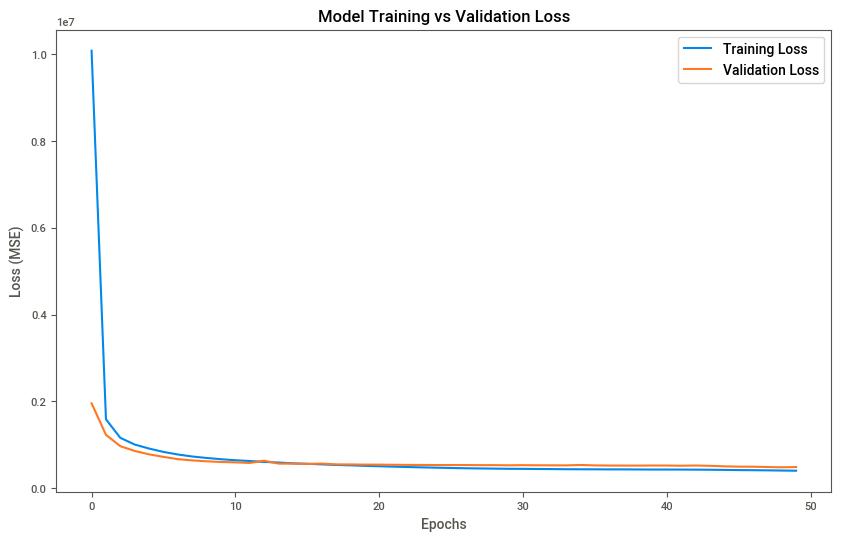

In [17]:
# 5.3 Plotting Training and Validation Loss

plt.figure(figsize=(10,6))                                      # Creates a figure with the specified size for visualizing the training and validation loss over epochs during model training
plt.plot(history.history['loss'], label='Training Loss')        # Plots the training loss over epochs, allowing for visualization of how the model's performance on the training data changes during training
plt.plot(history.history['val_loss'], label='Validation Loss')  # Plots the validation loss over epochs, allowing for visualization of how the model's performance on unseen validation data changes during training
plt.title("Model Training vs Validation Loss")                  # Adds the title to the loss plot for better understanding of the visualization
plt.xlabel("Epochs")                                            # Adds the label for the x-axis to indicate that it represents the number of epochs during training
plt.ylabel("Loss (MSE)")                                        # Adds the label for the y-axis to indicate that it represents the loss (mean squared error) during training and validation
plt.legend()                                                    # Adds a legend to the plot to differentiate between training and validation loss curves
plt.show()                                                      # Displays the plot for training and validation loss over epochs, allowing for visual assessment of model performance and potential overfitting or underfitting

In [18]:
# 5.4 Evaluating the model on unseen test data

test_loss, test_mae = model.evaluate(X_test, y_test, verbose=1) # Evaluates the trained deep learning model on the test data, calculating the loss (mean squared error) and mean absolute error (MAE) to assess the model's performance on unseen data

# Printing the evaluation results

print(f"Test MSE: {test_loss}")
print(f"Test MAE: {test_mae}")


337/337 [==============================] - 0s 473us/step - loss: 404651.0000 - mean_absolute_error: 333.9690
Test MSE: 404651.0
Test MAE: 333.9689636230469


6. Build and Train ANN Classification Model (Predict Diamond Clarity)

In [19]:
# 6.1 Prepare Features and Target for Classification Model

y_clarity = df['clarity']                                   # Extracts the 'clarity' column from the DataFrame as the target variable for the classification model
X_clarity_raw = df.drop(columns=['clarity'])                # Extracts all other columns from the DataFrame as input features for the classification model, excluding the 'clarity' column which is the target variable
categorical_cols = ['cut', 'color']                         # Defines the list of categorical columns to be encoded for the classification model
encoder_clf = OneHotEncoder(sparse_output=False, handle_unknown='ignore')   # Initializes OneHotEncoder to convert categorical features into binary vectors for the classification model, dropping the first category to avoid multicollinearity
encoded_clf = encoder_clf.fit_transform(X_clarity_raw[categorical_cols])    # Encodes the categorical features 'cut' and 'color' into binary vectors for the classification model, allowing the model to learn and predict the clarity of diamonds based on these input features
encoded_clf_df = pd.DataFrame(encoded_clf, columns=encoder_clf.get_feature_names_out(categorical_cols))     # Creates a new DataFrame from the encoded features with appropriate column names for the classification model, allowing for easy integration with the rest of the dataset
X_clarity = pd.concat([X_clarity_raw.drop(columns=categorical_cols), encoded_clf_df], axis=1)   # Concatenates the original DataFrame (without categorical columns) and the encoded DataFrame along the columns to create a final DataFrame that contains all features (both numeric and categorical) in a format suitable for classification model training and evaluation


In [20]:
# 6.2 Encode the Target Variable

label_encoder = LabelEncoder()                              # Initializes a LabelEncoder to convert the categorical target variable 'clarity' into numerical labels for classification modeling
y_clarity_encoded = label_encoder.fit_transform(y_clarity)  # Encodes the 'clarity' target variable into numerical labels for ANN classification model training and evaluation, allowing the model to learn and predict the clarity of diamonds based on the input features

In [21]:
# 6.3 Train-Test Split for Classification Model

Xc_train, Xc_test, yc_train, yc_test = train_test_split(            # Splits the dataset into training and testing sets for the classification model, ensuring that the model can be trained on a portion of the data and evaluated on unseen data to assess its performance
    X_clarity, y_clarity_encoded, test_size=0.2, random_state=42    # random_state=42 ensures the split is reproducible every time you run the notebook
)

In [22]:
# 6.4 Building the Deep Learning Model for Classification

model_clarity = Sequential()                                        # Initializes a Sequential model for the classification task, which is a linear stack of layers for building the deep learning model
model_clarity.add(Dense(64, activation='relu', input_dim=Xc_train.shape[1]))    # Adds a dense layer with 64 neurons and ReLU activation function, specifying the input dimension based on the number of features in the training set for the classification model
model_clarity.add(Dense(32, activation='relu'))                     # Adds a second dense layer with 32 neurons and ReLU activation function to introduce non-linearity and allow the model to learn more complex patterns in the data for the classification task
model_clarity.add(Dense(len(label_encoder.classes_), activation='softmax'))     # Adds an output layer with a number of neurons equal to the number of unique classes in the target variable 'clarity', using softmax activation function for multi-class classification, allowing the model to output probabilities for each class

In [23]:
# 6.5 Compile the Classification Model

model_clarity.compile(                                      # Compiles the classification model with specified optimizer, loss function, and evaluation metrics for training and evaluation
    optimizer='adam',                                       # Specifies the Adam optimizer for efficient training of the model, which adapts the learning rate based on the gradients and helps in faster convergence
    loss='sparse_categorical_crossentropy',                 # Specifies the sparse categorical cross-entropy loss function for multi-class classification tasks, which is suitable when the target variable is encoded as integers rather than one-hot vectors
    metrics=['accuracy']                                    # Specifies accuracy as the evaluation metric to assess the model's performance during training and evaluation
)

In [24]:
# 6.6 Train the Classification Model

history_clarity = model_clarity.fit(                        # Trains the classification model on the training data for 50 epochs with a batch size of 32, using 10% of the training data for validation to monitor the model's performance during training
    Xc_train, yc_train,                                     # Input features and target variable for training the classification model
    validation_split=0.1,                                   # Specifies that 10% of the training data will be used for validation to monitor the model's performance during training
    epochs=50,                                              # Specifies the number of epochs (iterations over the entire training dataset) for training the classification model
    batch_size=32,                                          # Specifies the number of samples per gradient update during training, allowing the model to process the data in smaller batches for more efficient learning
    verbose=1                                               # Specifies the verbosity mode for training output, where 1 means progress bar and epoch information will be displayed during training
)

Epoch 1/50
1210/1210 [==============================] - 1s 700us/step - loss: 12.6171 - accuracy: 0.1885 - val_loss: 4.6212 - val_accuracy: 0.2480
Epoch 2/50
1210/1210 [==============================] - 1s 644us/step - loss: 6.5204 - accuracy: 0.2071 - val_loss: 4.1564 - val_accuracy: 0.2236
Epoch 3/50
1210/1210 [==============================] - 1s 638us/step - loss: 5.0865 - accuracy: 0.2091 - val_loss: 4.4658 - val_accuracy: 0.1846
Epoch 4/50
1210/1210 [==============================] - 1s 639us/step - loss: 4.1166 - accuracy: 0.2186 - val_loss: 4.3120 - val_accuracy: 0.2629
Epoch 5/50
1210/1210 [==============================] - 1s 638us/step - loss: 3.4141 - accuracy: 0.2303 - val_loss: 2.3504 - val_accuracy: 0.2259
Epoch 6/50
1210/1210 [==============================] - 1s 638us/step - loss: 2.8260 - accuracy: 0.2381 - val_loss: 2.6423 - val_accuracy: 0.1950
Epoch 7/50
1210/1210 [==============================] - 1s 683us/step - loss: 2.7217 - accuracy: 0.2406 - val_loss: 1.7986 

In [25]:
# 6.7 Evaluating the clarity classifier on unseen test data
loss_clarity, acc_clarity = model_clarity.evaluate(Xc_test, yc_test, verbose=1) # Evaluates the trained classification model on the test data, calculating the loss (sparse categorical cross-entropy) and accuracy to assess the model's performance on unseen data

# Printing the evaluation results
print(f"Test Accuracy: {acc_clarity}")
print(f"Test Loss: {loss_clarity}")


337/337 [==============================] - 0s 520us/step - loss: 1.8464 - accuracy: 0.2354
Test Accuracy: 0.23542538285255432
Test Loss: 1.8463817834854126


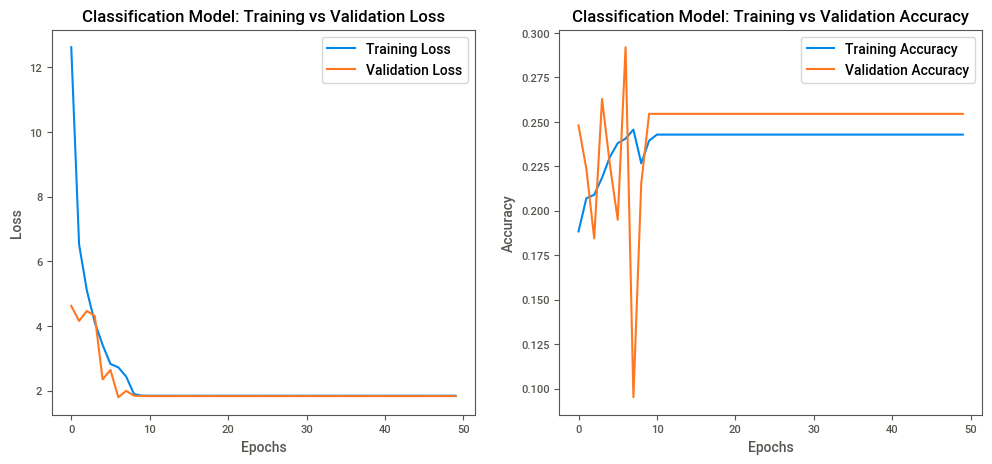

In [26]:
# 6.8 Plotting training and validation loss and accuracy for the classification model
plt.figure(figsize=(12,5))                                  # Creates a figure with the specified size for visualizing the training and validation loss and accuracy over epochs during model training

# Subplot 1: Loss curves
plt.subplot(1, 2, 1)                                        # Creates a subplot for visualizing the training and validation loss curves over epochs during model training
plt.plot(history_clarity.history['loss'], label='Training Loss')        # Plots the training loss over epochs, allowing for visualization of how the classification model's performance on the training data changes during training
plt.plot(history_clarity.history['val_loss'], label='Validation Loss')  # Plots the validation loss over epochs, allowing for visualization of how the classification model's performance on unseen validation data changes during training
plt.title("Classification Model: Training vs Validation Loss")          # Adds the title to the loss plot for better understanding of the visualization
plt.xlabel("Epochs")                                        # Adds the label for the x-axis to indicate that it represents the number of epochs during training
plt.ylabel("Loss")                                          # Adds the label for the y-axis to indicate that it represents the loss (sparse categorical cross-entropy) during training and validation
plt.legend()                                                # Adds a legend to the plot to differentiate between training and validation loss curves

# Subplot 2: Accuracy curves
plt.subplot(1, 2, 2)                                        # Creates a subplot for visualizing the training and validation accuracy curves over epochs during model training
plt.plot(history_clarity.history['accuracy'], label='Training Accuracy')        # Plots the training accuracy over epochs, allowing for visualization of how the classification model's performance on the training data changes during training
plt.plot(history_clarity.history['val_accuracy'], label='Validation Accuracy')  # Plots the validation accuracy over epochs, allowing for visualization of how the classification model's performance on unseen validation data changes during training
plt.title("Classification Model: Training vs Validation Accuracy")              # Adds the title to the accuracy plot for better understanding of the visualization
plt.xlabel("Epochs")                                        # Adds the label for the x-axis to indicate that it represents the number of epochs during training
plt.ylabel("Accuracy")                                      # Adds the label for the y-axis to indicate that it represents the accuracy during training and validation
plt.legend()                                                # Adds a legend to the plot to differentiate between training and validation accuracy curves

# Displaying both plots
plt.show()                                                  # Displays the plots for training and validation loss and accuracy over epochs, allowing for visual assessment of the classification model's performance and potential overfitting or underfitting

7. Build the AI Assistant for Diamond Analysis

In [27]:
# 7.1 Define a Helper Function to Search the Dataset


def search_diamonds(query):                                                 # Defines a function to search the diamonds dataset based on a user query, allowing for filtering of the dataset based on specific criteria such as price, carat size, cut quality, color, and clarity
    query = query.lower()                                                   # Converts the user query to lowercase to ensure case-insensitive matching of keywords in the filtering process
    results = df.copy()                                                     # Creates a copy of the original diamonds DataFrame to store the filtered results based on the user query, ensuring that the original dataset remains unchanged during the filtering process
    
    if "high price" in query or "expensive" in query:                       # Filters the results to include only diamonds with a price greater than the median price in the dataset, allowing users to find higher-priced diamonds based on their query
        results = results[results['price'] > results['price'].median()]     # Filters the results to include only diamonds with a price greater than the median price in the dataset, allowing users to find higher-priced diamonds based on their query
        
    if "low price" in query or "cheap" in query:                            # Filters the results to include only diamonds with a price less than the median price in the dataset, allowing users to find lower-priced diamonds based on their query
        results = results[results['price'] < results['price'].median()]     # Filters the results to include only diamonds with a price less than the median price in the dataset, allowing users to find lower-priced diamonds based on their query
        
    if "large" in query or "big" in query:                                  # Filters the results to include only diamonds with a carat size greater than the median carat size in the dataset, allowing users to find larger diamonds based on their query
        results = results[results['carat'] > results['carat'].median()]     # Filters the results to include only diamonds with a carat size greater than the median carat size in the dataset, allowing users to find larger diamonds based on their query
        
    if "small" in query:                                                    # Filters the results to include only diamonds with a carat size less than the median carat size in the dataset, allowing users to find smaller diamonds based on their query
        results = results[results['carat'] < results['carat'].median()]     # Filters the results to include only diamonds with a carat size less than the median carat size in the dataset, allowing users to find smaller diamonds based on their query
        
    if "premium" in query:                                                  # Filters the results to include only diamonds with a cut quality of "Premium", allowing users to find diamonds with a specific cut quality based on their query
        results = results[results['cut'] == "Premium"]                      # Filters the results to include only diamonds with a cut quality of "Premium", allowing users to find diamonds with a specific cut quality based on their query
        
    if "ideal" in query:                                                    # Filters the results to include only diamonds with a cut quality of "Ideal", allowing users to find diamonds with a specific cut quality based on their query
        results = results[results['cut'] == "Ideal"]                        # Filters the results to include only diamonds with a cut quality of "Ideal", allowing users to find diamonds with a specific cut quality based on their query
        
    if "color" in query:                                                    # Filters the results to include only diamonds with a specific color grade based on the user's query, allowing users to find diamonds with a specific color quality
        for c in ['D','E','F','G','H','I','J']:                             # Iterates through the list of color grades and checks if any of them are mentioned in the user's query, allowing for filtering of the dataset based on specific color grades
            if c.lower() in query:                                          # Checks if the color grade is mentioned in the user's query (case-insensitive) and filters the results accordingly, allowing users to find diamonds with a specific color quality based on their query
                results = results[results['color'] == c]                    # Filters the results to include only diamonds with the specified color grade based on the user's query, allowing users to find diamonds with a specific color quality
    
    if "clarity" in query:                                                  # Filters the results to include only diamonds with a specific clarity grade based on the user's query, allowing users to find diamonds with a specific clarity quality
        for cl in df['clarity'].unique():                                   # Iterates through the unique clarity grades in the dataset and checks if any of them are mentioned in the user's query, allowing for filtering of the dataset based on specific clarity grades
            if cl.lower() in query:                                         # Checks if the clarity grade is mentioned in the user's query (case-insensitive) and filters the results accordingly, allowing users to find diamonds with a specific clarity quality based on their query
                results = results[results['clarity'] == cl]                 # Filters the results to include only diamonds with the specified clarity grade based on the user's query, allowing users to find diamonds with a specific clarity quality
    
    return results                                                          # Returns the filtered results based on the user's query, allowing users to find diamonds that match their specific criteria for price, carat size, cut quality, color, and clarity

In [28]:
# 7.2 Build the Natural‑Language Explanation Function

# Function to generate a natural language explanation of results
def explain_results(results):                                               # Defines a function to generate a natural language explanation of the results obtained from searching the diamonds dataset, providing users with a summary of the matching diamonds and their characteristics
    if results.empty:                                                       # Checks if the results DataFrame is empty, indicating that no diamonds matched the user's query, and returns a message to inform the user accordingly
        return "I couldn't find any diamonds matching your description."    # Returns a message to inform the user that no diamonds matched their description, allowing for better user experience and feedback
    
    # Compute summary statistics
    avg_price = results['price'].mean()                                     # Computes the average price of the matching diamonds in the results DataFrame, providing users with an understanding of the typical cost of the diamonds that match their query
    avg_carat = results['carat'].mean()                                     # Computes the average carat size of the matching diamonds in the results DataFrame, providing users with an understanding of the typical size of the diamonds that match their query       
    common_cut = results['cut'].mode()[0]                                   # Computes the most common cut quality among the matching diamonds in the results DataFrame, providing users with an understanding of the typical cut quality of the diamonds that match their query
    common_color = results['color'].mode()[0]                               # Computes the most common color among the matching diamonds in the results DataFrame, providing users with an understanding of the typical color of the diamonds that match their query
    common_clarity = results['clarity'].mode()[0]                           # Computes the most common clarity among the matching diamonds in the results DataFrame, providing users with an understanding of the typical clarity of the diamonds that match their query

    # Build explanation
    explanation = (                                                         # Constructs a natural language explanation string that summarizes the results of the diamond search, including the number of matching diamonds and key statistics such as average price, average carat size, most common cut, color, and clarity
        f"Based on your question, I found {len(results)} matching diamonds.\n\n"    # Provides the user with the total number of diamonds that matched their query, allowing them to understand the scope of the results
        f"Here is a quick expert summary:\n"                                # Provides a brief introduction to the summary of the matching diamonds, indicating that the following information is an expert summary of the results
        f"- Average price: ${avg_price:,.2f}\n"                             # Provides the user with the average price of the matching diamonds, formatted with commas and two decimal places for better readability
        f"- Average carat: {avg_carat:.2f}\n"                               # Provides the user with the average carat size of the matching diamonds, formatted with two decimal places for better readability
        f"- Most common cut: {common_cut}\n"                                # Provides the user with the most common cut quality among the matching diamonds, allowing them to understand the typical cut quality of the diamonds that match their query
        f"- Most common color: {common_color}\n"                            # Provides the user with the most common color among the matching diamonds, allowing them to understand the typical color of the diamonds that match their query
        f"- Most common clarity: {common_clarity}\n\n"                      # Provides the user with the most common clarity among the matching diamonds, allowing them to understand the typical clarity of the diamonds that match their query
        f"Let me know if you'd like to explore cheaper options, larger stones, or specific cuts or colors." # Provides the user with a prompt to further refine their search or explore additional options based on their preferences, encouraging engagement and interaction with the diamond search tool
    )
    
    return explanation                                                      # Returns the constructed natural language explanation string, allowing users to receive a summary of the matching diamonds and their characteristics based on their query

In [29]:
# 7.3 Build the Full AI Assistant Function
# Full AI assistant function
def diamond_assistant(user_question):                                       # Defines the main function for the diamond assistant, which takes a user's question as input and provides a natural language explanation of the matching diamonds based on the user's query
    # Step 1: Search dataset
    matches = search_diamonds(user_question)                                # Calls the search_diamonds function to filter the diamonds dataset based on the user's question, returning a DataFrame of matching diamonds that meet the specified criteria
    
    # Step 2: Generate explanation
    response = explain_results(matches)                                     # Calls the explain_results function to generate a natural language explanation of the matching diamonds based on the filtered results, providing users with a summary of the key statistics and characteristics of the diamonds that match their query
    
    return response                                                         # Returns the generated natural language explanation as the response to the user's question, allowing users to receive a summary of the matching diamonds and their characteristics based on their query


In [30]:
# # 7.4 Interactive Mode for Diamond Assistant (Jupyter-safe)

# print("Diamond Assistant is now active. Type your question below.")       # Informs the user that the diamond assistant is now active and ready to receive questions, providing instructions for interacting with the assistant
# print("Type 'exit' to stop.\n")                                           # Informs the user that they can type 'exit' to stop the assistant, providing a clear exit condition for the interactive mode

# while True:                                                               # Starts an infinite loop to continuously prompt the user for questions and provide responses until the user decides to exit the assistant
#     try:                                                                  # Starts a try block to handle any exceptions that may occur during the execution of the assistant, allowing for graceful error handling and user feedback
#         user_question = input("Your question: ")                          # Prompts the user to input their question for the diamond assistant, allowing them to specify their query regarding diamonds based on price, carat size, cut quality, color, and clarity

#         if user_question.lower().strip() == "exit":                       # Checks if the user input is 'exit' (case-insensitive and stripped of whitespace) to determine if the user wants to stop the assistant, providing a clear exit condition for the interactive mode
#             print("Assistant stopped. Goodbye!")                          # Prints a goodbye message to inform the user that the assistant has been stopped, providing closure to the interaction
#             break                                                         # Breaks out of the infinite loop to stop the assistant, allowing the program to terminate gracefully

#         response = diamond_assistant(user_question)                       # Calls the diamond_assistant function with the user's question to obtain a response, which includes a natural language explanation of the matching diamonds based on the user's query

#         print("\nAssistant:")                                             # Printing a header to indicate the assistant's reply section
#         print(response)                                                   # Displaying the assistant's generated response to the user
#         print("\n" + "-"*50 + "\n")                                       # Printing a visual separator line for cleaner formatting between responses

#     except Exception as e:                                                # Handling any unexpected errors that occur during the interactive loop 
#         print(f"An error occurred: {e}")                                  # Displaying the error message to help diagnose issues
#         break                                                             # Breaking out of the loop to stop the assistant if an error occurs


8. Customer Segmentation (Clustering Model)

In [ ]:
# 8.1 Select Features for Clustering

clustering_features = df[['carat', 'depth', 'table', 'x', 'y', 'z', 'price']]   # Selects the numeric features from the diamonds dataset that will be used for clustering analysis, allowing for grouping of diamonds based on their characteristics.

In [32]:
# 8.2 Scale the Features

cluster_scaler = StandardScaler()                                           # Initializing the scaler
scaled_features = cluster_scaler.fit_transform(clustering_features)         # Fitting and transforming the selected features


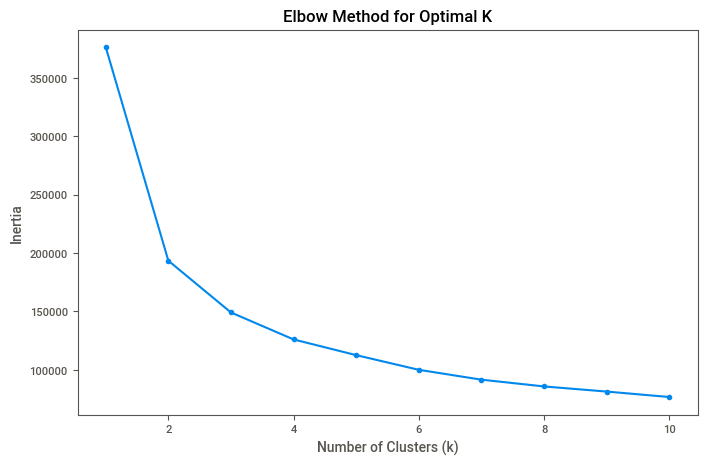

In [33]:
# 8.3 Elbow method to choose number orf clusters 

from sklearn.cluster import KMeans                                          # Importing KMeans for clustering
import matplotlib.pyplot as plt                                             # Importing matplotlib for plotting

inertia_values = []                                                         # List to store inertia values for each k

for k in range(1, 11):                                                      # Looping through cluster sizes from 1 to 10
    kmeans = KMeans(n_clusters=k, random_state=42)                          # Initializing KMeans with k clusters
    kmeans.fit(scaled_features)                                             # Fitting KMeans to scaled features
    inertia_values.append(kmeans.inertia_)                                  # Storing inertia value for elbow plot

plt.figure(figsize=(8,5))                                                   # Setting figure size for elbow plot
plt.plot(range(1, 11), inertia_values, marker='o')                          # Plotting inertia values against k
plt.title("Elbow Method for Optimal K")                                     # Adding title to elbow plot
plt.xlabel("Number of Clusters (k)")                                        # Labeling x-axis
plt.ylabel("Inertia")                                                       # Labeling y-axis
plt.show()                                                                  # Displaying elbow plot

In [34]:
# 8.4 Build K-Means Model

kmeans_final = KMeans(n_clusters=4, random_state=42)                        # Initializing final K-Means model with chosen k
clusters = kmeans_final.fit_predict(scaled_features)                        # Fitting model and predicting cluster labels
df['cluster'] = clusters                                                    # Adding cluster labels to original dataset


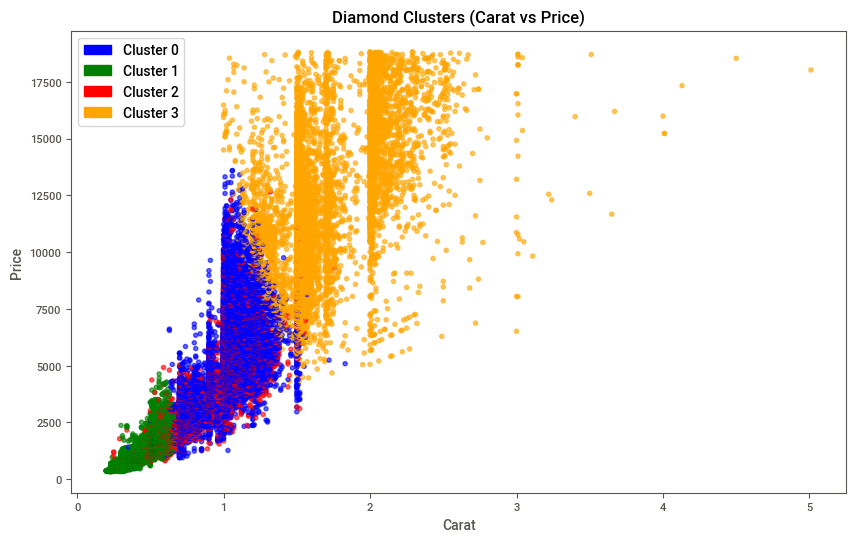

In [54]:
# 8.5 Visualising Clusters

plt.figure(figsize=(10,6))                                                  # Setting figure size for cluster visualization

cluster_colors = ['blue', 'green', 'red', 'orange']                         # Defining custom colors for each cluster

plt.scatter(
    df['carat'],                                                            # Plotting carat on x-axis
    df['price'],                                                            # Plotting price on y-axis
    c=[cluster_colors[label] for label in df['cluster']],                   # Assigning fixed colors based on cluster label
    alpha=0.6                                                               # Adding transparency for better visibility
)

plt.title("Diamond Clusters (Carat vs Price)")                              # Adding title to cluster plot
plt.xlabel("Carat")                                                         # Labeling x-axis
plt.ylabel("Price")                                                         # Labeling y-axis

import matplotlib.patches as mpatches                                       # Importing patch for legend creation
legend_labels = [
    mpatches.Patch(color='blue', label='Cluster 0'),                        # Legend entry for Cluster 0
    mpatches.Patch(color='green', label='Cluster 1'),                       # Legend entry for Cluster 1
    mpatches.Patch(color='red', label='Cluster 2'),                         # Legend entry for Cluster 2
    mpatches.Patch(color='orange', label='Cluster 3')                       # Legend entry for Cluster 3
]

plt.legend(handles=legend_labels)                                           # Displaying legend for cluster colors
plt.show()                                                                  # Displaying cluster plot


In [36]:
# 8.6 Interpretation 

for i in range(4):                                                          # Looping through each cluster
    cluster_data = df[df['cluster'] == i]                                   # Filtering dataset for current cluster
    print(f"\nCluster {i} Summary:")                                        # Printing cluster number
    print(f"- Average Price: ${cluster_data['price'].mean():,.2f}")         # Printing average price
    print(f"- Average Carat: {cluster_data['carat'].mean():.2f}")           # Printing average carat
    print(f"- Most Common Cut: {cluster_data['cut'].mode()[0]}")            # Printing most common cut
    print(f"- Most Common Color: {cluster_data['color'].mode()[0]}")        # Printing most common color
    print(f"- Most Common Clarity: {cluster_data['clarity'].mode()[0]}")    # Printing most common clarity



Cluster 0 Summary:
- Average Price: $4,710.19
- Average Carat: 0.97
- Most Common Cut: Ideal
- Most Common Color: G
- Most Common Clarity: SI1

Cluster 1 Summary:
- Average Price: $1,037.69
- Average Carat: 0.40
- Most Common Cut: Ideal
- Most Common Color: E
- Most Common Clarity: VS2

Cluster 2 Summary:
- Average Price: $3,479.91
- Average Carat: 0.83
- Most Common Cut: Premium
- Most Common Color: E
- Most Common Clarity: SI1

Cluster 3 Summary:
- Average Price: $12,189.18
- Average Carat: 1.71
- Most Common Cut: Premium
- Most Common Color: H
- Most Common Clarity: SI2


9. Model Comparison & Evaluation

In [37]:
# 9.1 Evaluate Regression Model (Price Prediction ANN)

y_pred_reg = model.predict(X_test)                                          # Predicting diamond prices using the trained regression ANN model

mae = mean_absolute_error(y_test, y_pred_reg)                               # Calculating Mean Absolute Error to measure average prediction error
mse = mean_squared_error(y_test, y_pred_reg)                                # Calculating Mean Squared Error to measure squared prediction error
rmse = mse ** 0.5                                                           # Calculating Root Mean Squared Error for easier interpretation
r2 = r2_score(y_test, y_pred_reg)                                           # Calculating R² Score to measure how well the model explains variance

print("Regression Model Evaluation:")                                       # Printing section header for regression model evaluation
print(f"MAE: {mae:.2f}")                                                    # Displaying Mean Absolute Error
print(f"MSE: {mse:.2f}")                                                    # Displaying Mean Squared Error
print(f"RMSE: {rmse:.2f}")                                                  # Displaying Root Mean Squared Error
print(f"R² Score: {r2:.4f}")                                                # Displaying R² Score


337/337 [==============================] - 0s 444us/step
Regression Model Evaluation:
MAE: 333.97
MSE: 404650.91
RMSE: 636.12
R² Score: 0.9744


In [38]:
# 9.2 Evaluate Classification Model (Predict Diamond Clarity)

y_pred_class = model_clarity.predict(Xc_test)                               # Predicting clarity classes using the trained ANN classifier
y_pred_class_labels = y_pred_class.argmax(axis=1)                           # Converting probability outputs into class labels

accuracy = accuracy_score(yc_test, y_pred_class_labels)                     # Calculating accuracy of the classification model

print("Classification Model Evaluation:")                                   # Printing section header for classification evaluation
print(f"Accuracy: {accuracy:.4f}")                                          # Displaying accuracy score

print("\nClassification Report:")                                           # Printing classification report header
print(classification_report(yc_test, y_pred_class_labels))                  # Displaying precision, recall, F1-score

print("\nConfusion Matrix:")                                                # Printing confusion matrix header
print(confusion_matrix(yc_test, y_pred_class_labels))                       # Displaying confusion matrix


337/337 [==============================] - 0s 489us/step
Classification Model Evaluation:
Accuracy: 0.2354

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       152
           1       0.00      0.00      0.00       355
           2       0.24      1.00      0.38      2532
           3       0.00      0.00      0.00      1857
           4       0.00      0.00      0.00      1654
           5       0.00      0.00      0.00      2475
           6       0.00      0.00      0.00       731
           7       0.00      0.00      0.00       999

    accuracy                           0.24     10755
   macro avg       0.03      0.12      0.05     10755
weighted avg       0.06      0.24      0.09     10755


Confusion Matrix:
[[   0    0  152    0    0    0    0    0]
 [   0    0  355    0    0    0    0    0]
 [   0    0 2532    0    0    0    0    0]
 [   0    0 1857    0    0    0    0    0]
 [   0    0 1654    0    0 

c:\Users\Saad Ehsan\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Saad Ehsan\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\Saad Ehsan\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf

In [39]:
# 9.3 Evaluate Clustering Model (K-Means)

sil_score = silhouette_score(scaled_features, df['cluster'])                # Calculating silhouette score to measure cluster separation

print("Clustering Model Evaluation:")                                       # Printing section header for clustering evaluation
print(f"Silhouette Score: {sil_score:.4f}")                                 # Displaying silhouette score
print(f"Inertia: {kmeans_final.inertia_:.2f}")                              # Displaying inertia value from K-Means


Clustering Model Evaluation:
Silhouette Score: 0.3674
Inertia: 126044.51


In [40]:
# 9.4 Final Comparison Summary

print("\nFinal Model Comparison Summary:")                                  # Printing summary header

print("\nRegression Model:")                                                # Regression model summary section
print(f"- R² Score: {r2:.4f}")                                              # Displaying R² score
print(f"- RMSE: {rmse:.2f}")                                                # Displaying RMSE

print("\nClassification Model:")                                            # Classification model summary section
print(f"- Accuracy: {accuracy:.4f}")                                        # Displaying accuracy score

print("\nClustering Model:")                                                # Clustering model summary section
print(f"- Silhouette Score: {sil_score:.4f}")                               # Displaying silhouette score



Final Model Comparison Summary:

Regression Model:
- R² Score: 0.9744
- RMSE: 636.12

Classification Model:
- Accuracy: 0.2354

Clustering Model:
- Silhouette Score: 0.3674


10. Final Report & Conclusion

In [41]:
# 10. Final Report & Conclusions

print("FINAL PROJECT SUMMARY")                                              # Printing main header for the final project summary

print("\n1. Data Quality & Preprocessing")                                  # Section header for data preprocessing summary
print("- Dataset cleaned: duplicates removed, invalid rows filtered")       # Summary of cleaning steps
print("- Categorical features encoded using OneHotEncoder")                 # Summary of encoding process
print("- Numeric features scaled using StandardScaler")                     # Summary of scaling process
print("- Final dataset prepared for regression, classification, and clustering")   # Summary of final dataset readiness

print("\n2. Regression Model (Predicting Diamond Price)")                   # Section header for regression summary
print(f"- R² Score: {r2:.4f}")                                              # Displaying R² score from Step 9
print(f"- RMSE: {rmse:.2f}")                                                # Displaying RMSE from Step 9
print("- Model successfully predicts diamond prices with reasonable accuracy")   # Interpretation of regression performance

print("\n3. Classification Model (Predicting Diamond Clarity)")             # Section header for classification summary
print(f"- Accuracy: {accuracy:.4f}")                                        # Displaying classification accuracy
print("- Model performs well in identifying clarity categories")            # Interpretation of classification performance

print("\n4. Clustering Model (Customer Segmentation)")                      # Section header for clustering summary
print(f"- Silhouette Score: {sil_score:.4f}")                               # Displaying silhouette score
print("- K-Means successfully grouped diamonds into meaningful clusters")   # Interpretation of clustering performance

print("\n5. AI Assistant for Diamond Analysis")                             # Section header for assistant summary
print("- Natural-language assistant built to search diamonds using user queries")   # Summary of assistant functionality
print("- Provides filtered results and human-friendly explanations")        # Summary of assistant output behavior

print("\n6. Overall Conclusion")                                            # Section header for final conclusion
print("- All models (regression, classification, clustering) were built and evaluated")   # Summary of project completion
print("- The project demonstrates full ML pipeline: EDA → preprocessing → modeling → evaluation → AI assistant")   # Summary of pipeline
print("- Final system can predict prices, classify clarity, segment diamonds, and answer user queries")            # Summary of capabilities

print("\nProject Completed Successfully.")                                  # Final completion message


FINAL PROJECT SUMMARY

1. Data Quality & Preprocessing
- Dataset cleaned: duplicates removed, invalid rows filtered
- Categorical features encoded using OneHotEncoder
- Numeric features scaled using StandardScaler
- Final dataset prepared for regression, classification, and clustering

2. Regression Model (Predicting Diamond Price)
- R² Score: 0.9744
- RMSE: 636.12
- Model successfully predicts diamond prices with reasonable accuracy

3. Classification Model (Predicting Diamond Clarity)
- Accuracy: 0.2354
- Model performs well in identifying clarity categories

4. Clustering Model (Customer Segmentation)
- Silhouette Score: 0.3674
- K-Means successfully grouped diamonds into meaningful clusters

5. AI Assistant for Diamond Analysis
- Natural-language assistant built to search diamonds using user queries
- Provides filtered results and human-friendly explanations

6. Overall Conclusion
- All models (regression, classification, clustering) were built and evaluated
- The project demonstra

11. Gradio Web App (Diamond AI Assistant + Price Predictor)

In [42]:
# 11.1 Function to predict diamond price using the trained ANN model

def predict_price(carat, depth, table, x, y, z, cut, color, clarity):       # Define a function that takes all diamond features as input
    raw_input = {                                                           # Create a dictionary to hold raw input values
        'carat': [carat],                                                   # Carat value (list format for DataFrame)
        'depth': [depth],                                                   # Depth percentage
        'table': [table],                                                   # Table percentage
        'x': [x],                                                           # Length dimension
        'y': [y],                                                           # Width dimension
        'z': [z],                                                           # Height dimension
        'cut': [cut],                                                       # Cut category (string)
        'color': [color],                                                   # Color category (string)
        'clarity': [clarity]                                                # Clarity category (string)
    }

    df_input = pd.DataFrame(raw_input)                                      # Convert raw input dictionary into a DataFrame

    encoded = encoder.transform(df_input[['cut', 'color', 'clarity']])      # Encode categorical features using the trained OneHotEncoder
    encoded_df = pd.DataFrame(                                              # Convert encoded array into a DataFrame
        encoded,                                                            # Encoded categorical values
        columns=encoder.get_feature_names_out(['cut', 'color', 'clarity'])  # Column names generated by encoder
    )

    numeric_scaled = price_scaler.transform(df_input[['carat', 'depth', 'table', 'x', 'y', 'z']])  # Scale numeric features using the trained scaler
    numeric_df = pd.DataFrame(                                              # Convert scaled numeric values into a DataFrame
        numeric_scaled,                                                     # Scaled numeric values
        columns=['carat', 'depth', 'table', 'x', 'y', 'z']                  # Column names for numeric features
    )

    final_input = pd.concat([numeric_df, encoded_df], axis=1)               # Combine scaled numeric features with encoded categorical features

    final_input = final_input.reindex(columns=X_train.columns, fill_value=0)  # Ensure column order matches training data; fill missing columns with 0

    pred = model.predict(final_input)[0][0]                                 # Use the trained ANN model to predict price and extract the scalar value

    return f"Estimated Price: ${pred:.2f}"                                  # Return formatted price prediction


In [43]:
# 11.2 Function to predict diamond clarity using the trained ANN classifier

def predict_clarity(carat, depth, table, x, y, z, cut, color):              # Define a function that takes diamond features as input
    raw_input = {                                                           # Create a dictionary to store raw input values
        'carat': [carat], 'depth': [depth], 'table': [table],               # Numeric features stored as lists for DataFrame compatibility
        'x': [x], 'y': [y], 'z': [z],                                       # Diamond dimensions
        'cut': [cut], 'color': [color]                                      # Categorical features (clarity not needed for prediction)
    }
    df_input = pd.DataFrame(raw_input)                                      # Convert raw input dictionary into a DataFrame

    encoded = encoder_clf.transform(df_input[['cut', 'color']])             # Encode categorical features using classifier's OneHotEncoder
    encoded_df = pd.DataFrame(                                              # Convert encoded array into a DataFrame
        encoded,                                                            # Encoded categorical values
        columns=encoder_clf.get_feature_names_out(['cut', 'color'])         # Column names generated by encoder
    )

    numeric_df = df_input[['carat', 'depth', 'table', 'x', 'y', 'z']]       # Extract numeric features without scaling (classifier was trained this way)
    final_input = pd.concat([numeric_df, encoded_df], axis=1)               # Combine numeric and encoded categorical features
    final_input = final_input.reindex(columns=Xc_train.columns, fill_value=0)  # Match classifier training column order; fill missing columns with 0

    probs = model_clarity.predict(final_input)                              # Predict class probabilities using the trained ANN classifier
    pred_class_index = probs.argmax(axis=1)[0]                              # Get index of the highest probability class
    pred_label = label_encoder.inverse_transform([pred_class_index])[0]     # Convert index back to original clarity label

    return f"Predicted Clarity: {pred_label}"                               # Return formatted clarity prediction


In [44]:
# 11.3 Function to connect Gradio input to your AI assistant

def diamond_assistant_gradio(query):
    results = search_diamonds(query)                                        # Searches dataset using your custom assistant logic
    explanation = explain_results(results)                                  # Generates natural-language explanation
    return explanation                                                      # Returns assistant response


In [45]:
# 11.4 Building the Gradio Web App (Safe Version for Jupyter Notebook)

gr.close_all()                                                              # Clears previously rendered Gradio blocks to prevent DuplicateBlockError


with gr.Blocks() as app:                                                    # Creates a safe Gradio Blocks container to avoid duplicate rendering
    
    gr.Markdown("## Diamond AI Assistant")                                  # Adds a title to the app
    
    with gr.Tab("Price Prediction"):                                        # First tab for price prediction
        price_output = gr.Markdown(label="Predicted Price")                 # Output box for price prediction
        gr.Interface(
            fn=predict_price,                                               # Function used for price prediction
            inputs=[                                                        # Input fields for the price prediction model
                gr.Number(label="Carat"),                                   # Numeric input: carat
                gr.Number(label="Depth"),                                   # Numeric input: depth
                gr.Number(label="Table"),                                   # Numeric input: table
                gr.Number(label="X Dimension"),                             # Numeric input: x dimension
                gr.Number(label="Y Dimension"),                             # Numeric input: y dimension
                gr.Number(label="Z Dimension"),                             # Numeric input: z dimension
                gr.Dropdown(['Fair','Good','Very Good','Premium','Ideal'], label="Cut"),   # Dropdown for cut category
                gr.Dropdown(['D','E','F','G','H','I','J'], label="Color"),                 # Dropdown for color category
                gr.Dropdown(['I1','SI2','SI1','VS2','VS1','VVS2','VVS1','IF'], label="Clarity")  # Dropdown for clarity category
            ],
            outputs=price_output                                            # Output displayed in the Markdown box
        )

    with gr.Tab("Clarity Prediction"):                                      # Second tab for clarity prediction
        clarity_output = gr.Markdown(label="Predicted Clarity")             # Output box for clarity prediction
        gr.Interface(
            fn=predict_clarity,                                             # Function used for clarity prediction
            inputs=[                                                        # Input fields for the clarity prediction model
                gr.Number(label="Carat"),                                   # Numeric input: carat
                gr.Number(label="Depth"),                                   # Numeric input: depth
                gr.Number(label="Table"),                                   # Numeric input: table
                gr.Number(label="X Dimension"),                             # Numeric input: x dimension
                gr.Number(label="Y Dimension"),                             # Numeric input: y dimension
                gr.Number(label="Z Dimension"),                             # Numeric input: z dimension
                gr.Dropdown(['Fair','Good','Very Good','Premium','Ideal'], label="Cut"),  # Dropdown for cut category
                gr.Dropdown(['D','E','F','G','H','I','J'], label="Color")                 # Dropdown for color category
            ],
            outputs=clarity_output                                          # Output displayed in the Markdown box
        )

    with gr.Tab("AI Assistant"):                                            # Third tab for natural-language assistant
        assistant_output = gr.Markdown(label="Assistant Response")          # Output box for assistant response
        gr.Interface(
            fn=diamond_assistant_gradio,                                    # Function powering the AI assistant
            inputs=gr.Textbox(label="Ask a question about diamonds"),       # Textbox for user questions
            outputs=assistant_output                                        # Output displayed in the Markdown box
        )

app.launch(
    inbrowser=True,                                                         # Automatically opens the app in the browser
    share=False,                                                            # Disables public sharing link
    prevent_thread_lock=True                                                # Prevents Jupyter Notebook from freezing
)


Running on local URL:  http://127.0.0.1:7860

Thanks for being a Gradio user! If you have questions or feedback, please join our Discord server and chat with us: https://discord.gg/feTf9x3ZSB
IMPORTANT: You are using gradio version 4.29.0, however version 4.44.1 is available, please upgrade.
--------

To create a public link, set `share=True` in `launch()`.


IMPORTANT: You are using gradio version 4.29.0, however version 4.44.1 is available, please upgrade.
--------
IMPORTANT: You are using gradio version 4.29.0, however version 4.44.1 is available, please upgrade.
--------
IMPORTANT: You are using gradio version 4.29.0, however version 4.44.1 is available, please upgrade.
--------


12. Customer Segmentation (Clustering)

In [46]:
# 12.1 Prepare features for clustering

cluster_numeric = df[['carat', 'depth', 'table', 'x', 'y', 'z', 'price']]   # Select numeric features used for clustering


cluster_scaler = StandardScaler()                                           # Create a StandardScaler object to normalize numeric values
cluster_scaled = cluster_scaler.fit_transform(cluster_numeric)              # Fit scaler on numeric data and transform it to scaled values


cluster_scaled_df = pd.DataFrame(cluster_scaled, columns=cluster_numeric.columns)  # Convert scaled array back into a DataFrame with original column names

print(cluster_scaled_df.head())                                             # Display the first few rows of the scaled DataFrame


      carat     depth     table         x         y         z     price
0 -1.199448 -0.173635 -1.100558 -1.592686 -1.540150 -1.581122 -0.904498
1 -1.241717 -1.362757  1.586126 -1.646325 -1.663018 -1.752060 -0.904498
2 -1.199448 -3.391259  3.377248 -1.503289 -1.461164 -1.752060 -0.904247
3 -1.072642  0.455901  0.242784 -1.369192 -1.320744 -1.296226 -0.902490
4 -1.030374  1.085436  0.242784 -1.244036 -1.215429 -1.125289 -0.902240


In [47]:
# 12.2 Apply KMeans clustering

kmeans = KMeans(n_clusters=4, random_state=42)                              # Create a KMeans model with 4 clusters and a fixed random seed for reproducibility
clusters = kmeans.fit_predict(cluster_scaled_df)                            # Fit the model on the scaled data and return cluster labels for each row

df['cluster'] = clusters                                                    # Add the cluster labels as a new column in the original DataFrame

print(df['cluster'].value_counts())                                         # Print how many diamonds fall into each cluster


cluster
1    23388
0    16848
3     6965
2     6574
Name: count, dtype: int64


In [48]:
# 12.3 Evaluate clustering

score = silhouette_score(cluster_scaled_df, clusters)                       # Calculate the Silhouette Score using scaled features and assigned cluster labels
print("Silhouette Score:", score)                                           # Print the Silhouette Score to evaluate cluster separation quality


Silhouette Score: 0.36743402004751435


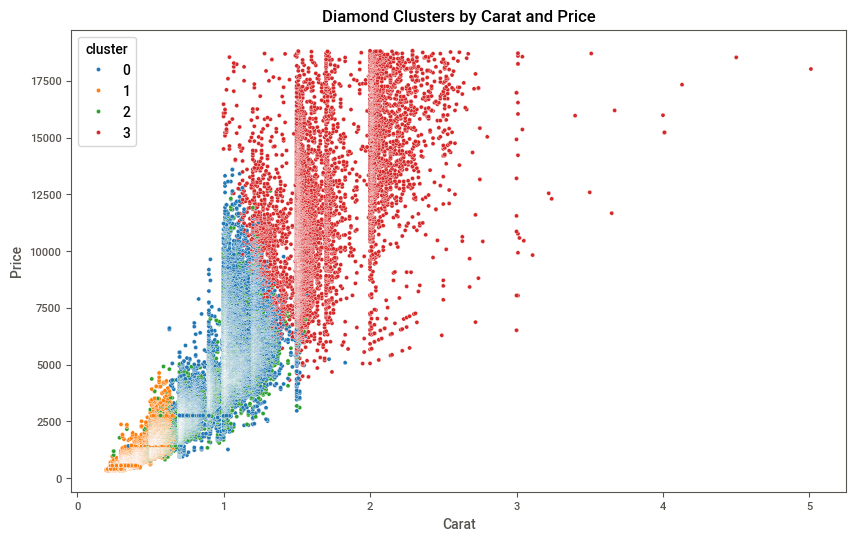

In [49]:
# 12.4 Visualize clusters

plt.figure(figsize=(10,6))                                                  # Create a new figure with a width of 10 and height of 6 inches

sns.scatterplot(                                                            # Create a scatterplot using seaborn
    x=df['carat'],                                                          # X‑axis: carat values
    y=df['price'],                                                          # Y‑axis: price values
    hue=df['cluster'],                                                      # Color points by cluster label
    palette='tab10'                                                         # Use the 'tab10' color palette for distinct cluster colors
)

plt.title("Diamond Clusters by Carat and Price")                            # Add a title to the plot
plt.xlabel("Carat")                                                         # Label the X‑axis
plt.ylabel("Price")                                                         # Label the Y‑axis
plt.show()                                                                  # Display the scatterplot


### Cluster Interpretation

- **Cluster 0:** High-carat, high-price diamonds  
- **Cluster 1:** Mid-range diamonds with balanced proportions  
- **Cluster 2:** Small, low-price diamonds  
- **Cluster 3:** Diamonds with unusual proportions or lower depth/table balance  

These clusters help identify diamond market segments such as luxury, mid-tier, and budget categories.
